# Random Forest Experiments (Parts B and C)

This notebook completes the coding experiments and report for Parts B and C. Part A is not repeated. Run the cells from top to bottom.

The Heart Disease CSV and Intel image folders are already in `random_forest_results`. The notebook reads them from there, keeps the original dataset folders in place, and saves its result tables and plots in a separate `random_forest_results/experiment_outputs` folder. To keep the image experiment manageable on a beginner computer, it uses at most 150 training images per class; set `MAX_IMAGES_PER_CLASS = None` to use all images.


## Short paper summary

Breiman's 2001 paper presents Random Forests as collections of randomized decision trees. Bootstrap samples provide different training data for trees, and randomly selected features at each split make trees less alike. Voting across trees reduces the effect of an individual tree's mistakes. Breiman also discusses the strength of trees and their correlation as important factors in generalization, and describes out-of-bag samples as a way to estimate error without a separate validation set.


In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TREE_COUNTS = [1, 10, 50, 100, 300]

# Find the assignment folder whether the notebook is opened from the workspace or its subfolder.
NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / 'data.csv').exists() and (NOTEBOOK_DIR / 'lab-assignment').exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / 'lab-assignment'
DATA_DIR = NOTEBOOK_DIR / 'random_forest_results'
RESULTS_DIR = DATA_DIR / 'experiment_outputs'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Reading datasets from:', DATA_DIR.resolve())
print('Saving plots and result tables to:', RESULTS_DIR.resolve())

Reading datasets from: E:\lab-assignment\random_forest_results
Saving plots and result tables to: E:\lab-assignment\random_forest_results\experiment_outputs


## 1. Heart Disease UCI dataset

The local Cleveland CSV contains patient measurements and a diagnosis (`condition`) column. The target is converted to two classes (0 = no disease, 1 = disease present), any missing-value markers are removed, and the data is split into 80% training and 20% testing with class proportions preserved. Features are standardized for the SVM; tree models use the original numeric features.


In [3]:
# Load the Heart Disease CSV that is already in the assignment folder.
heart_path = DATA_DIR / 'heart_cleveland_upload.csv'
if not heart_path.exists():
    raise FileNotFoundError(f'Heart Disease CSV not found: {heart_path}')

heart = pd.read_csv(heart_path)
# The downloaded Cleveland CSV calls the diagnosis column "condition".
# Convert any missing-value markers to NaN and remove incomplete rows.
heart = heart.replace('?', np.nan).dropna().copy()
heart = heart.apply(pd.to_numeric)
target_column = 'condition' if 'condition' in heart.columns else 'target'
heart[target_column] = (heart[target_column] > 0).astype(int)
X_heart = heart.drop(columns=target_column)
y_heart = heart[target_column]
X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart, y_heart, test_size=0.2, random_state=RANDOM_STATE, stratify=y_heart
)
print('Heart dataset file:', heart_path)
print('Rows after removing missing values:', len(heart))
print('Train rows:', len(X_heart_train), '| Test rows:', len(X_heart_test))
heart.head()

Heart dataset file: e:\lab-assignment\random_forest_results\heart_cleveland_upload.csv
Rows after removing missing values: 297
Train rows: 237 | Test rows: 60


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


## 2. Intel Image Classification dataset

The six Intel scene categories are stored in `random_forest_results/seg_train/seg_train`. We read labeled images from the training directory, resize each to 24 × 24 pixels, scale RGB values to 0–1, flatten the pixels into numeric features, and make a stratified 80/20 split. The image cap is a practical speed setting, not a requirement of the dataset; raise it or set it to `None` for a larger experiment. This simple pixel-based approach keeps the experiment understandable, although it is not as powerful as modern deep-learning image models.


In [4]:
MAX_IMAGES_PER_CLASS = 150  # Set to None to use every image in each class.
IMAGE_SIZE = (24, 24)
intel_dir = DATA_DIR / 'seg_train' / 'seg_train'
if not intel_dir.exists():
    raise FileNotFoundError(
        f'Intel images not found at {intel_dir}. The folder should contain one folder per scene class.'
    )

image_extensions = {'.jpg', '.jpeg', '.png'}
image_features = []
image_labels = []
image_rng = np.random.default_rng(RANDOM_STATE)
for class_folder in sorted(path for path in intel_dir.iterdir() if path.is_dir()):
    image_paths = sorted(path for path in class_folder.iterdir() if path.suffix.lower() in image_extensions)
    if MAX_IMAGES_PER_CLASS is not None and len(image_paths) > MAX_IMAGES_PER_CLASS:
        chosen_indices = image_rng.choice(len(image_paths), size=MAX_IMAGES_PER_CLASS, replace=False)
        image_paths = [image_paths[index] for index in chosen_indices]
    for image_path in image_paths:
        with Image.open(image_path) as image:
            resized = image.convert('RGB').resize(IMAGE_SIZE)
            image_features.append(np.asarray(resized, dtype=np.float32).reshape(-1) / 255.0)
            image_labels.append(class_folder.name)

X_image = np.asarray(image_features, dtype=np.float32)
y_image = np.asarray(image_labels)
if len(np.unique(y_image)) < 2:
    raise ValueError('At least two class folders with images are needed.')
X_image_train, X_image_test, y_image_train, y_image_test = train_test_split(
    X_image, y_image, test_size=0.2, random_state=RANDOM_STATE, stratify=y_image
)
print('Image folder:', intel_dir)
print('Image count:', len(X_image), '| Classes:', sorted(np.unique(y_image)))
print('Image feature count:', X_image.shape[1])
print('Train rows:', len(X_image_train), '| Test rows:', len(X_image_test))

Image folder: e:\lab-assignment\random_forest_results\seg_train\seg_train
Image count: 900 | Classes: [np.str_('buildings'), np.str_('forest'), np.str_('glacier'), np.str_('mountain'), np.str_('sea'), np.str_('street')]
Image feature count: 1728
Train rows: 720 | Test rows: 180


## 3. Decision Tree, Random Forest, and SVM comparison

We measure test accuracy and time spent fitting each model on the training data. The Random Forest uses scikit-learn defaults (`n_estimators=100`); the SVM uses an RBF kernel and standardizes its inputs. Timing depends on your computer.


In [5]:
def compare_models(X_train, X_test, y_train, y_test):
    models = {
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest (default)': RandomForestClassifier(random_state=RANDOM_STATE),
        'SVM (RBF)': make_pipeline(StandardScaler(), SVC()),
    }
    rows = []
    for name, model in models.items():
        start = time.perf_counter()
        model.fit(X_train, y_train)
        training_seconds = time.perf_counter() - start
        accuracy = accuracy_score(y_test, model.predict(X_test))
        rows.append({'Model': name, 'Test accuracy': accuracy, 'Training time (seconds)': training_seconds})
    return pd.DataFrame(rows)

heart_comparison = compare_models(X_heart_train, X_heart_test, y_heart_train, y_heart_test)
image_comparison = compare_models(X_image_train, X_image_test, y_image_train, y_image_test)

print('Heart Disease UCI')
display(heart_comparison.round(4))
print('Intel Image Classification')
display(image_comparison.round(4))
heart_comparison.to_csv(RESULTS_DIR / 'heart_model_comparison.csv', index=False)
image_comparison.to_csv(RESULTS_DIR / 'intel_model_comparison.csv', index=False)

Heart Disease UCI


,Model,Test accuracy,Training time (seconds)
0,Decision Tree,0.7833,0.0122
1,Random Forest (default),0.8833,0.1859
2,SVM (RBF),0.9000,0.0109


Intel Image Classification


,Model,Test accuracy,Training time (seconds)
0,Decision Tree,0.3944,1.0259
1,Random Forest (default),0.5333,1.6985
2,SVM (RBF),0.5389,0.2666


## 4. Effect of the number of trees

The following experiment uses the requested tree counts and plots test accuracy. Increasing the tree count usually makes the result less dependent on the randomness of a small number of trees, but takes more training time.


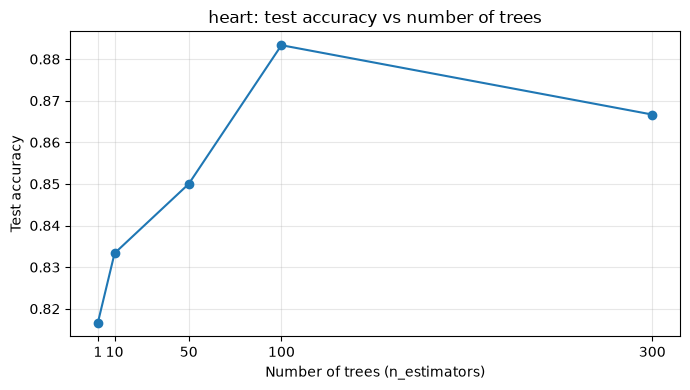

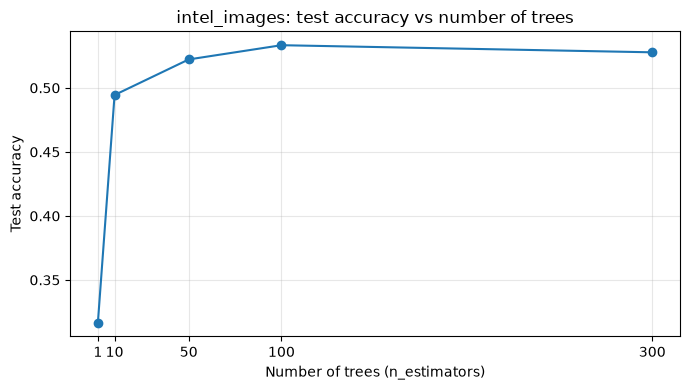

Heart sweep results


,n_estimators,Test accuracy,Training time (seconds)
0,1,0.8167,0.0078
1,10,0.8333,0.0266
2,50,0.8500,0.0938
3,100,0.8833,0.1747
4,300,0.8667,0.5301


Image sweep results


,n_estimators,Test accuracy,Training time (seconds)
0,1,0.3167,0.0185
1,10,0.4944,0.1670
2,50,0.5222,0.8341
3,100,0.5333,1.7260
4,300,0.5278,4.9586


In [6]:
def run_tree_sweep(X_train, X_test, y_train, y_test, dataset_name):
    rows = []
    for tree_count in TREE_COUNTS:
        model = RandomForestClassifier(n_estimators=tree_count, random_state=RANDOM_STATE)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        training_seconds = time.perf_counter() - start
        accuracy = accuracy_score(y_test, model.predict(X_test))
        rows.append({'n_estimators': tree_count, 'Test accuracy': accuracy, 'Training time (seconds)': training_seconds})
    results = pd.DataFrame(rows)
    results.to_csv(RESULTS_DIR / f'{dataset_name}_tree_sweep.csv', index=False)
    plt.figure(figsize=(7, 4))
    plt.plot(results['n_estimators'], results['Test accuracy'], marker='o')
    plt.xticks(TREE_COUNTS)
    plt.xlabel('Number of trees (n_estimators)')
    plt.ylabel('Test accuracy')
    plt.title(f'{dataset_name}: test accuracy vs number of trees')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'{dataset_name}_accuracy_vs_trees.png', dpi=150)
    plt.show()
    return results

heart_sweep = run_tree_sweep(X_heart_train, X_heart_test, y_heart_train, y_heart_test, 'heart')
image_sweep = run_tree_sweep(X_image_train, X_image_test, y_image_train, y_image_test, 'intel_images')
print('Heart sweep results')
display(heart_sweep.round(4))
print('Image sweep results')
display(image_sweep.round(4))

## 5. Simple stability check

We train three 100-tree forests with different random seeds. A smaller standard deviation of their test accuracies means the scores changed less across these runs. This is a small illustrative check, not a formal statistical test.


In [7]:
def check_forest_stability(X_train, X_test, y_train, y_test, dataset_name):
    scores = []
    for seed in [0, 1, 2]:
        model = RandomForestClassifier(n_estimators=100, random_state=seed)
        model.fit(X_train, y_train)
        scores.append(accuracy_score(y_test, model.predict(X_test)))
    return {
        'Dataset': dataset_name,
        'Accuracies across seeds': scores,
        'Mean accuracy': np.mean(scores),
        'Standard deviation': np.std(scores),
    }

stability_results = pd.DataFrame([
    check_forest_stability(X_heart_train, X_heart_test, y_heart_train, y_heart_test, 'Heart Disease'),
    check_forest_stability(X_image_train, X_image_test, y_image_train, y_image_test, 'Intel Images'),
])
display(stability_results.round(4))
stability_results.to_csv(RESULTS_DIR / 'forest_stability.csv', index=False)

,Dataset,Accuracies across seeds,Mean accuracy,Standard deviation
0,Heart Disease,"[0.85, 0.85, 0.85]",0.8500,0.0000
1,Intel Images,"[0.511111, 0.511111, 0.527778]",0.5167,0.0079


In [9]:
# Turn the measurements above into a short report using your actual results.
comparisons = {
    'Heart Disease UCI': heart_comparison,
    'Intel Image Classification': image_comparison,
}
sweeps = {
    'Heart Disease UCI': heart_sweep,
    'Intel Image Classification': image_sweep,
}

def markdown_table(table):
    columns = [str(column) for column in table.columns]
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    for _, row in table.iterrows():
        values = []
        for column in table.columns:
            value = row[column]
            if pd.api.types.is_integer_dtype(table[column]):
                values.append(str(int(value)))
            elif isinstance(value, (float, np.floating)):
                values.append(f'{value:.4f}')
            else:
                values.append(str(value))
        lines.append('| ' + ' | '.join(values) + ' |')
    return '\n'.join(lines)

report_lines = [
    '# Random Forest Experiments: Results and Discussion',
    '',
    '## Breiman’s main ideas',
    'Breiman’s 2001 paper presents Random Forests as collections of randomized decision trees. Bootstrap samples give trees different training examples, while randomly selecting features at each split helps keep trees less correlated. Strong trees make useful predictions, and lower correlation means their errors are less likely to repeat together. Combining their votes can reduce variance and improve generalization compared with relying on one tree. Breiman also describes out-of-bag examples as an internal way to estimate error.',
    '',
    '## Framework and preprocessing',
    '- Heart Disease: the Cleveland subset has patient measurements and a diagnosis label. We used the local CSV, removed missing rows, converted diagnosis to binary, and used a stratified 80/20 split.',
    '- Intel Images: six outdoor-scene classes. We resized RGB images to 24 × 24, scaled pixel values to 0–1, sampled up to 150 images per class, and used a stratified 80/20 split. Flattening pixels keeps the exercise simple, but it does not capture image structure as well as a deep-learning method.',
    '- Models: Decision Tree, Random Forest with scikit-learn defaults, and RBF SVM with standardized inputs. Accuracy uses held-out test data; time is model fitting time.',
    '',
]

for dataset_name, table in comparisons.items():
    best = table.loc[table['Test accuracy'].idxmax()]
    forest = table.loc[table['Model'] == 'Random Forest (default)'].iloc[0]
    tree = table.loc[table['Model'] == 'Decision Tree'].iloc[0]
    svm = table.loc[table['Model'] == 'SVM (RBF)'].iloc[0]
    report_lines.extend([
        f'## {dataset_name}: model comparison',
        '',
        markdown_table(table),
        '',
        f"The highest test accuracy was from **{best['Model']}** ({best['Test accuracy']:.3f}). "
        f"The Random Forest scored {forest['Test accuracy']:.3f} and took {forest['Training time (seconds)']:.3f} seconds to fit; "
        f"the Decision Tree scored {tree['Test accuracy']:.3f} in {tree['Training time (seconds)']:.3f} seconds, "
        f"and the SVM scored {svm['Test accuracy']:.3f} in {svm['Training time (seconds)']:.3f} seconds. "
        f"Compared with one tree, the forest improved accuracy by {forest['Test accuracy'] - tree['Test accuracy']:.3f} "
        f"but took longer to fit. The SVM was {'more' if svm['Test accuracy'] > forest['Test accuracy'] else 'less'} accurate than the forest on this split.",
        '',
    ])

for dataset_name, table in sweeps.items():
    first = table.iloc[0]
    last = table.iloc[-1]
    best = table.loc[table['Test accuracy'].idxmax()]
    first_count = int(first['n_estimators'])
    report_lines.extend([
        f'## {dataset_name}: number of trees',
        '',
        markdown_table(table),
        '',
        f"Accuracy was {first['Test accuracy']:.3f} with {first_count} {'tree' if first_count == 1 else 'trees'}, "
        f"{last['Test accuracy']:.3f} with {int(last['n_estimators'])} trees, and highest ({best['Test accuracy']:.3f}) "
        f"at {int(best['n_estimators'])} trees in this test. The 300-tree fit took {last['Training time (seconds)']:.3f} seconds. "
        'In general, accuracy improved as the forest grew and then leveled off or fluctuated slightly. A finite test set can make accuracy fluctuate, so not every step is expected to improve.',
        '',
    ])

report_lines.extend([
    '## Stability across random seeds',
    '',
    markdown_table(stability_results),
    '',
    'The standard deviation summarizes how much the three forest test scores varied across random seeds; a smaller value indicates more consistent scores in this check. Results suggest that the larger ensemble is less sensitive to its random choices, although this is a small illustrative check, not a formal statistical test.',
])
report_path = RESULTS_DIR / 'experiment_report.md'
report_path.write_text('\n'.join(report_lines), encoding='utf-8')
print('Saved report to:', report_path.resolve())
print('\n'.join(report_lines))

Saved report to: E:\lab-assignment\random_forest_results\experiment_outputs\experiment_report.md
# Random Forest Experiments: Results and Discussion

## Breiman’s main ideas
Breiman’s 2001 paper presents Random Forests as collections of randomized decision trees. Bootstrap samples give trees different training examples, while randomly selecting features at each split helps keep trees less correlated. Strong trees make useful predictions, and lower correlation means their errors are less likely to repeat together. Combining their votes can reduce variance and improve generalization compared with relying on one tree. Breiman also describes out-of-bag examples as an internal way to estimate error.

## Framework and preprocessing
- Heart Disease: the Cleveland subset has patient measurements and a diagnosis label. We used the local CSV, removed missing rows, converted diagnosis to binary, and used a stratified 80/20 split.
- Intel Images: six outdoor-scene classes. We resized RGB images to

## 6. End-to-end report and discussion

The preceding cells form the full experiment framework: load and prepare each dataset, make a reproducible stratified train/test split, fit the Decision Tree, default Random Forest, and scaled SVM, sweep the forest size, then check forest stability across random seeds. Accuracy is measured only on the held-out test data; training time measures fitting only, so results can vary slightly by computer.

The next code cell writes a short report containing your actual results and plain-language comparisons. Use those measured values rather than copying example numbers. The tables and plots are also saved in `random_forest_results/experiment_outputs`.

### Key ideas and interpretation

Breiman's 2001 paper describes Random Forests as ensembles of randomized decision trees. Bootstrap samples provide different training examples to trees; random feature selection at each split helps keep trees less correlated. Strong individual trees make useful predictions, while lower correlation means their errors are less likely to repeat together. Majority voting can therefore reduce variance and make predictions more stable than relying on one tree. Breiman identifies tree strength and correlation as central to generalization, and also describes out-of-bag examples as an internal error estimate.

- **Number of trees:** Accuracy often improves or becomes steadier as more trees vote, then improvements level off. It need not increase at every tested count. More trees increase fit time.
- **Decision Tree vs Random Forest:** A single tree is quick but can be sensitive to its training data. A forest commonly improves generalization by averaging many trees, usually at a higher training cost. Confirm this against your tables.
- **SVM comparison:** Compare the three measured test accuracies and fitting times for each dataset. The SVM uses standardized inputs; Decision Trees and Random Forests do not need feature scaling.
- **Randomness and stability:** Similar test accuracies across different forest seeds indicate less sensitivity to the random choices made during training. This small check illustrates stability, not a formal statistical test.
